# Rounding experiment: the paper's Figure 9 with a corrected Adafactor

Figure 9 of the paper (Appendix A.3, *Stochastic rounding enables bfloat16 training*) repeats the Figure 1a Adafactor runs (lm11m, 598M tokens of FineWeb-Edu, 5% warmup + cosine, Adafactor at the tuned peak learning rate and $t_2$ of each batch size) with the model weights stored in (1) float32, (2) bfloat16 with closest rounding, (3) bfloat16 with stochastic rounding, the optimizer state always in float32, and plots the final validation loss against the batch size. With closest rounding the loss leaves the chart (> 5.0) at $B \le 16$; stochastic rounding brings bfloat16 close to float32 at every batch size.

The paper's Adafactor has a bug (see the sharpness notebook): `get_optimizer` converts $t_2$ to $\beta_2 = 0.5^{BT/t_2}$ and passes it to `scale_by_factored_rms` as `decay_rate`, which is the *exponent* $c$ of Adafactor's power-law schedule $\beta_{2,t} = 1-(t+1)^{-c}$, not an EMA coefficient; at $B \le 16$ the second moment is a near-cumulative average of $g^2$ over the whole run. This notebook asks whether the rounding result survives a corrected Adafactor.

**Corrected Adafactor** (`rounding/scripts/common.py`): upstream's chain (factored float32 second moment, update clipping at RMS 1, relative step size, no first moment) with `scale_by_factored_rms` given a `decay_rate_fn` that realises the bias-corrected EMA with constant $\beta_2 = 0.5^{BT/t_2}$, i.e. the second moment the paper's Adam (`optax.adamw`) uses: as a schedule $\beta_{2,t} = 1 - (1-\beta_2)/(1-\beta_2^{t})$, $t = 1, 2, \dots$. Nothing else changes: configs, model, data order, training step and the weight rounding are upstream's (`pretraining/optimizer.py: apply_updates`, `utils.to_bf16_stochastic`); matmuls in TF32 as in the sharpness runs.

**Hyperparameters.** The paper did not release its tuned Adafactor values. By decision, the runs reuse the sharpness bracket's quarter-budget optima of the *paper's* Adafactor (`sharpness/runs/bracket/best.json`) unchanged, so the batch sizes are the bracket's $B \in \{1, 16, 256, 4096\}$ rather than the paper's $\{1, 4, 16, 64, 256, 1024\}$, and the values are not tuned for the corrected implementation. In particular the bracket picked $t_2 = 1$M tokens at every $B$ (a tie-break at small $B$ under the bug), which the corrected implementation takes literally: $\beta_2 = 0.9996$ (B=1), $0.9943$ (16), $0.913$ (256), $0.234$ (4096).

**Runs** (`rounding/scripts/figure9.py`, 12 runs at the paper's full budget, order $B = 16, 256, 4096, 1$): fp32, bf16 (closest) and bf16sr (stochastic) at each $B$. If the fp32 run diverges, the learning rate is stepped down one index of the paper's Adafactor grid ($\times B^{0.3}$) for all three precisions of that $B$ (reported as `lr_steps_down`); a diverged bf16 run counts as a result (loss $\infty$, drawn off the top of the chart as the paper's closest-rounding points). Outputs in `rounding/runs/figure9/` (per run: `steps.f32`, `curve.json` = loss on 1M validation tokens every $2^{25}$ tokens, `eval.json`, final weights), W&B group `rounding`. Launch in the background with `rounding/scripts/run_bg.sh rounding bash rounding/scripts/run_figure9.sh`; the first cell below collects what has finished (and trains the rest in place when no background job is running).


In [1]:
import json, subprocess, sys
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
here = Path.cwd().resolve()                                             # works from the repo root, this folder, or any subfolder
REPO = next((p for p in (here, *here.parents) if (p / 'rounding' / 'scripts').is_dir()), Path.home() / 'src' / 'batch-size')
assert (REPO / 'rounding' / 'scripts').is_dir(), f'repo not found from {here}; set REPO by hand'
sys.path.insert(0, str(REPO))
from rounding.scripts import figure9

# the 12 runs, memoised: finished runs are read back; missing ones are trained here (hours) unless the detached job is running
busy = subprocess.run(['systemctl', '--user', 'is-active', '--quiet', 'rounding']).returncode == 0
if busy: print('the background unit "rounding" is running: collecting finished runs only')
summary = figure9.main(['--no-train'] if busy else [])


B=16: lr 0.009557 (grid index 3, 1 steps down) t2 1M  fp32 3.7558  bf16 5.3178  bf16sr 3.7908


B=256: lr 0.02196 (grid index 3, 0 steps down) t2 1M  fp32 3.9891  bf16 3.9936  bf16sr 4.0135


B=4096: lr 0.05044 (grid index 3, 0 steps down) t2 1M  fp32 5.7461  bf16 5.8022  bf16sr 5.8051


B=1: lr 0.00416 (grid index 3, 0 steps down) t2 1M  fp32 3.6706  bf16 diverged  bf16sr 3.8094


all runs finished


In [2]:
PREC = {'fp32': 'FP32', 'bf16': 'BF16 (closest)', 'bf16sr': 'BF16 (stochastic)'}
rows = [dict(B=s['batch_size'], peak_lr=s['peak_lr'], lr_steps_down=s['lr_steps_down'], t2=f"{s['t2'] / 1e6:g}M", beta2=0.5 ** (s['batch_size'] * 512 / s['t2']),
             **{PREC[p]: (r['loss'] if r['state'] == 'done' else f"{r['state']} ({r['loss']:.3g})" if r['state'] == 'diverged' else r['state']) for p, r in s['runs'].items()}) for s in summary.values()]
table = pd.DataFrame(rows).sort_values('B').set_index('B')
display(table.style.format({'peak_lr': '{:.4g}', 'beta2': '{:.4f}', **{v: lambda x: f'{x:.4f}' if isinstance(x, float) else x for v in PREC.values()}}))

# the paper's Figure 9 (its Adafactor, its tuned hyperparameters, TPU v4), digitised from the arXiv v4 SVG (+-0.01); None = above the chart (> 5.0)
PAPER_BS = [1, 4, 16, 64, 256, 1024]
PAPER = {'FP32': [3.69, 3.72, 3.77, 3.87, 4.07, 4.6], 'BF16 (stochastic)': [3.84, 3.81, 3.82, 3.9, 4.06, 4.61], 'BF16 (closest)': [None, None, None, 4.24, 4.11, 4.62]}
display(pd.DataFrame(PAPER, index=pd.Index(PAPER_BS, name='B (paper)')).T)


,peak_lr,lr_steps_down,t2,beta2,FP32,BF16 (closest),BF16 (stochastic)
B,,,,,,,
1,0.00416,0,1M,0.9996,3.6706,diverged (88.5),3.8094
16,0.009557,1,1M,0.9943,3.7558,5.3178,3.7908
256,0.02196,0,1M,0.9132,3.9891,3.9936,4.0135
4096,0.05044,0,1M,0.2337,5.7461,5.8022,5.8051


B (paper),1,4,16,64,256,1024
FP32,3.69,3.72,3.77,3.87,4.07,4.60
BF16 (stochastic),3.84,3.81,3.82,3.90,4.06,4.61
BF16 (closest),NaN,NaN,NaN,4.24,4.11,4.62


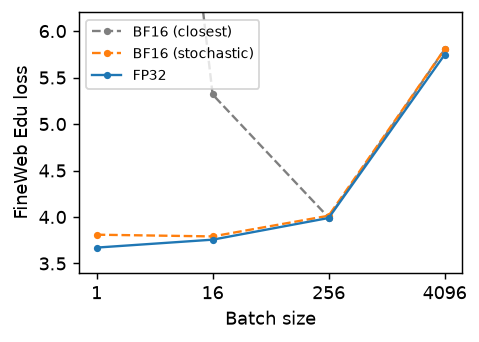

In [3]:
# the paper's Figure 9, same layout: final validation loss against the batch size, one line per weight precision
STYLE = {'bf16': dict(label='BF16 (closest)', color='tab:gray', ls='--'), 'bf16sr': dict(label='BF16 (stochastic)', color='tab:orange', ls='--'), 'fp32': dict(label='FP32', color='tab:blue', ls='-')}
BS = sorted(s['batch_size'] for s in summary.values())
done = lambda p: [(B, summary[str(B)]['runs'][p]['loss']) for B in BS if summary[str(B)]['runs'].get(p, {}).get('state') in ('done', 'diverged')]
finite = [summary[str(B)]['runs'][p]['loss'] for p in ('fp32', 'bf16sr') for B in BS if summary[str(B)]['runs'].get(p, {}).get('state') == 'done']   # the y range follows the fp32 and stochastic curves,
lo, hi = (np.floor(min(finite) * 5) / 5 - 0.2, np.ceil(max(finite) * 5) / 5 + 0.2) if finite else (3.6, 5.0)   # closest-rounding points may leave the chart (paper)
fig, ax = plt.subplots(figsize=(3.8, 2.6), dpi=130)
for p, st in STYLE.items():
    pts = done(p)
    if pts: ax.plot([B for B, _ in pts], [y if (np.isfinite(y) and y < hi + 10) else hi + 10 for _, y in pts], marker='o', ms=3, lw=1.3, **st)   # diverged: off the top
ax.set_xscale('log', base=2); ax.set_xticks(BS); ax.set_xticklabels([str(B) for B in BS]); ax.minorticks_off()
from matplotlib.lines import Line2D
ax.set_ylim(lo, hi); ax.set_xlabel('Batch size'); ax.set_ylabel('FineWeb Edu loss')
ax.legend(handles=[Line2D([], [], marker='o', ms=3, lw=1.3, **st) for st in STYLE.values()], loc='upper left', fontsize=8)
figures = REPO / 'rounding' / 'runs' / 'figures'; figures.mkdir(parents=True, exist_ok=True)
plt.rcParams['pdf.fonttype'] = 42                                                       # embed TrueType so the text stays editable text in the PDF
fig.savefig(figures / 'figure9.pdf', bbox_inches='tight'); fig.savefig(figures / 'figure9.svg', bbox_inches='tight')   # vector, for slides
fig.savefig(figures / 'figure9.png', dpi=300, bbox_inches='tight')
plt.show()


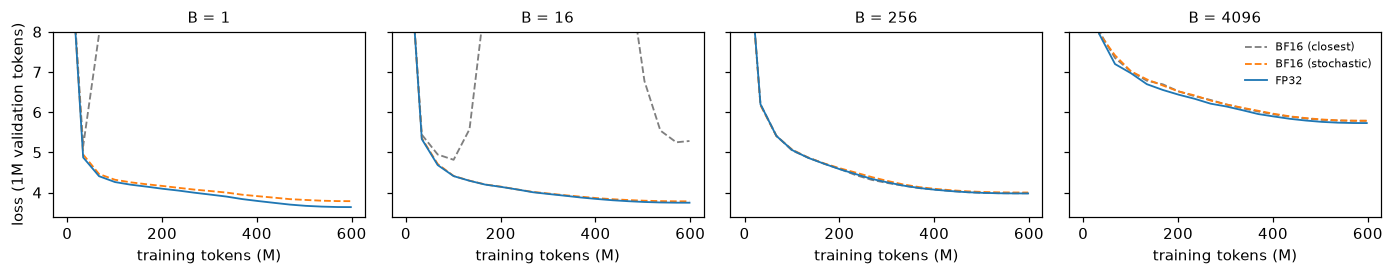

In [4]:
# not in the paper: the training curves (loss on the first 1M validation tokens every 2^25 tokens) of the runs so far
fig, axs = plt.subplots(1, len(BS), figsize=(3.2 * len(BS), 2.6), dpi=110, sharey=True)
for ax, B in zip(np.atleast_1d(axs), BS):
    for p, st in STYLE.items():
        r = summary[str(B)]['runs'].get(p)
        if r and (REPO / r['dir'] / 'curve.json').exists():
            cur = json.load(open(REPO / r['dir'] / 'curve.json')); ax.plot([e['tokens'] / 1e6 for e in cur], [e['curve_loss'] for e in cur], lw=1.2, **st)
    ax.set_title(f'B = {B}', fontsize=10); ax.set_xlabel('training tokens (M)'); ax.set_ylim(3.4, 8.0)
from matplotlib.lines import Line2D
np.atleast_1d(axs)[0].set_ylabel('loss (1M validation tokens)')
np.atleast_1d(axs)[-1].legend(handles=[Line2D([], [], lw=1.2, **st) for st in STYLE.values()], fontsize=7, frameon=False)
plt.tight_layout(); plt.show()
